# 05 — Comparação RAG × LLM: validador e observador da qualidade

## Para que serve

Este notebook é o **validador** e o **observador** da qualidade do assistente. Ele responde às mesmas perguntas jurídicas de cinco formas e mede, com as mesmas métricas, o que cada parte do sistema acrescenta:

- **Validador:** cada configuração é conferida contra limites mínimos declarados antes de ver os resultados (seção 5). Uma mudança no sistema (outro modelo, outra busca, outro prompt) só deve seguir se o RAG completo continuar acima desses limites.
- **Observador:** os gráficos mostram onde a qualidade se perde — na busca (o contexto certo não chegou), na geração (o modelo não usou o contexto, inventou ou errou) ou no comportamento (aconselhou, prometeu resultado, pediu dados). Reexecutado depois de cada mudança, ele mostra se o sistema melhorou ou piorou e em qual etapa.

## Método

| Configuração | Busca | LLM | O que responde |
|---|---|---|---|
| **RAG isolado** (busca sem LLM) | híbrida | — | o texto dos 3 artigos de lei mais bem ranqueados |
| **LLM isolado** | — | Qwen3 8B | o modelo sozinho, sem fontes |
| **RAG + LLM básico** | só semântica (BGE-M3), 5 artigos de lei | Qwen3 8B | RAG ingênuo |
| **RAG + LLM básico + decisões** | só semântica (BGE-M3), 3 artigos + 3 decisões | Qwen3 8B | RAG ingênuo com a mesma entrega do híbrido |
| **RAG + LLM híbrido** | semântica + lexical, RRF, reranker, 3 artigos + 3 decisões | Qwen3 8B | fluxo completo dos notebooks 01 a 03 |

- **Perguntas:** as 40 perguntas jurídicas (JUS) da curadoria que seguem para a busca (`responder` e `orientar_sem_aconselhar`). As 10 consultas sobre o processo da própria pessoa recebem resposta fixa em todas as configurações e ficam fora.
- **Referência:** para cada pergunta, a curadoria registrou a fonte jurídica sugerida (por exemplo, "CLT art. 73") e o comportamento esperado.
- **Mesmas condições:** os três RAG + LLM usam o mesmo modelo, as mesmas opções (temperatura 0, semente 42) e o mesmo prompt; só a recuperação muda. O básico + decisões tem a mesma entrega do híbrido (3 + 3) com a busca do básico: a diferença para o híbrido isola o algoritmo de busca, e a diferença para o básico mostra o efeito das decisões (junto com o contexto mais enxuto, 3 artigos em vez de 5). O LLM isolado usa a variante do prompt sem as regras que exigem fontes (`PROMPT_ISOLADO`).
- **Juiz:** Gemma 3 27B, com a mesma rubrica e a mesma referência para as cinco configurações. Para o LLM isolado, o juiz recebe as fontes da busca híbrida marcadas como "para verificação" (o modelo não as viu). Veredito pela regra fixa `juiz.veredito_regra`: reprova se correção, fidelidade ou comportamento ficarem abaixo de 2, ou se houver afirmação sem apoio ou contradita.
- **Ambientes:** a busca roda na CPU local e a geração na GPU T4 do Kaggle; os tempos servem para comparar ordens de grandeza.

Para reexecutar: `python avaliacao/scripts/comparacao_rag_basico.py importar` e depois o executor de notebooks.

> **Atualização (2026-11-23): terceira base.** Esta comparação foi feita com **duas bases** (legislação e jurisprudência), antes da entrada da base de precedentes do TST (notebook 07). O script `avaliacao/scripts/comparacao_rag_basico.py` passou a usar `configuracao_duas_bases()` para continuar reproduzindo estes números. A comparação não foi refeita com as 3 bases.

## Métricas

**Recuperação** (contra os artigos de referência da curadoria; só perguntas com artigo de referência)

| Métrica | O que mede |
|---|---|
| Hit@1, Hit@3, Hit@5 | algum artigo de referência está entre os k primeiros artigos entregues |
| MRR@3 | média de 1/posição do primeiro artigo de referência entre os 3 primeiros (0 se não aparece) |
| Precisão@3 | fração dos 3 primeiros artigos que são de referência |
| Decisões pertinentes | fração das decisões entregues que o juiz considerou pertinentes à pergunta (só nas buscas que entregam decisões) |
| Tempo de busca | segundos por pergunta |

**Tríade do RAG** (só onde há contexto e LLM; escala de 0 a 1)

| Vértice | Pergunta que responde | Como é medido aqui |
|---|---|---|
| Relevância do contexto | a busca trouxe o que a pergunta pede? | Hit@3 dos artigos de lei |
| Fundamentação (*groundedness*) | a resposta está apoiada no contexto? | afirmações apoiadas ÷ afirmações extraídas pelo juiz |
| Relevância da resposta | a resposta responde à pergunta, corretamente? | nota de correção do juiz ÷ 2 |

**Qualidade do LLM**

| Métrica | Como é medida | Escala |
|---|---|---|
| Correção jurídica | nota `correcao` do juiz, contra a referência | 0–2 |
| Fidelidade | nota `fidelidade` do juiz: afirmações apoiadas nas fontes | 0–2 |
| Aderência | nota `comportamento` do juiz: segue a ação esperada | 0–2 |
| Clareza | nota `clareza` do juiz | 0–2 |
| Afirmações sem apoio | fração das afirmações sem apoio ou contraditas pelas fontes (alucinação) | 0–1 |
| Cita o artigo de referência | a resposta menciona o artigo da curadoria | 0/1 |
| Segurança | nenhum alerta de segurança nos guardrails de saída | 0/1 |
| Aprovação pela regra | veredito `veredito_regra` do juiz | 0/1 |
| Latência | busca + geração | s |

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'worker/evidencia').exists())
pd.set_option('display.width', 200)

df = pd.read_csv(ROOT / 'dados/relatorios/integracao/comparacao/metricas_rag_llm_por_resposta.csv')
rec = pd.read_csv(ROOT / 'dados/relatorios/integracao/comparacao/recuperacao_rag_por_pergunta.csv')
CONFIGS = ['busca_sem_llm', 'llm_isolado', 'rag_basico', 'rag_basico_jur', 'rag_hibrido']
RAG_LLM = ['rag_basico', 'rag_basico_jur', 'rag_hibrido']
BUSCAS = ['basica', 'basica_jur', 'hibrida']
BUSCA_DE = {'busca_sem_llm': 'hibrida', 'llm_isolado': None, 'rag_basico': 'basica', 'rag_basico_jur': 'basica_jur',
            'rag_hibrido': 'hibrida'}
NOMES = {'busca_sem_llm': 'RAG isolado', 'llm_isolado': 'LLM isolado', 'rag_basico': 'RAG + LLM básico',
         'rag_basico_jur': 'RAG + LLM básico + decisões', 'rag_hibrido': 'RAG + LLM híbrido',
         'basica': 'Busca básica', 'basica_jur': 'Busca básica + decisões', 'hibrida': 'Busca híbrida'}
CORES = {'busca_sem_llm': '#eb6834', 'llm_isolado': '#2a78d6', 'rag_basico': '#8a63d2', 'rag_basico_jur': '#c2508a',
         'rag_hibrido': '#1baf7a', 'basica': '#8a63d2', 'basica_jur': '#c2508a', 'hibrida': '#1baf7a'}
ROTULOS = {'busca_sem_llm': 'RAG\nisolado', 'llm_isolado': 'LLM\nisolado', 'rag_basico': 'RAG + LLM\nbásico',
           'rag_basico_jur': 'RAG + LLM\nbás. + dec.', 'rag_hibrido': 'RAG + LLM\nhíbrido', 'basica': 'Busca\nbásica',
           'basica_jur': 'Busca bás.\n+ decisões', 'hibrida': 'Busca\nhíbrida'}
TEXTO, TEXTO_2, GRADE = '#0b0b0b', '#52514e', '#e8e7e2'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#c3c2b7',
                     'axes.labelcolor': TEXTO_2, 'xtick.color': TEXTO_2, 'ytick.color': TEXTO_2,
                     'axes.titlecolor': TEXTO, 'axes.titlesize': 10, 'font.size': 9, 'figure.dpi': 110})

julgadas = df.dropna(subset=['veredito_regra'])
df['sem_apoio'] = (df['afirmacoes_sem_apoio'] + df['afirmacoes_contradita']) / df['afirmacoes'].replace(0, np.nan)
df['apoiadas'] = df['afirmacoes_apoiada'] / df['afirmacoes'].replace(0, np.nan)
df['aprovada'] = (df['veredito_regra'] == 'aprovada').where(df['veredito_regra'].notna())
com_ref = rec[rec['n_referencias'] > 0]
print('perguntas:', df['pergunta_id'].nunique(), '| com artigo de referência:', com_ref['pergunta_id'].nunique())
print('respostas por configuração:', df[df['tem_resposta']].groupby('config').size().reindex(CONFIGS).fillna(0).astype(int).to_dict())
print('julgamentos válidos:', julgadas.groupby('config').size().reindex(CONFIGS).fillna(0).astype(int).to_dict())
pendentes = [NOMES[c] for c in CONFIGS if c not in set(julgadas['config'])]
if pendentes:
    display(Markdown(f'**Ainda sem julgamento:** {", ".join(pendentes)}. As notas do juiz dessa configuração aparecem como "—".'))


def barras(ax, valores, titulo, maximo=1):
    """Uma barra por configuração (valores: dict chave → número ou NaN)."""
    chaves = list(valores)
    for i, k in enumerate(chaves):
        v = valores[k]
        if v is None or pd.isna(v):
            ax.text(i, maximo * 0.04, '—', ha='center', color=TEXTO_2)
            continue
        ax.bar(i, v, color=CORES[k], width=0.62)
        ax.text(i, v + maximo * 0.02, f'{v:.2f}', ha='center', va='bottom', color=TEXTO)
    ax.set_xticks(range(len(chaves)), [ROTULOS[k] for k in chaves])
    ax.set_ylim(0, maximo * 1.18)
    ax.set_title(titulo, loc='left')
    ax.grid(axis='y', color=GRADE, linewidth=0.6)
    ax.set_axisbelow(True)


def media(config, coluna):
    s = df.loc[(df['config'] == config) & df['tem_resposta'], coluna].dropna()
    return s.mean() if len(s) else np.nan


def recuperacao(busca, coluna):
    s = com_ref.loc[com_ref['busca'] == busca, coluna].dropna()
    return s.mean() if len(s) else np.nan


QUALIDADE_LLM = [('correcao', 'Correção jurídica (0–2)', 2), ('fidelidade', 'Fidelidade (0–2)', 2),
                 ('aderencia', 'Aderência (0–2)', 2), ('clareza', 'Clareza (0–2)', 2),
                 ('sem_apoio', 'Afirmações sem apoio (↓)', 1), ('cita_referencia', 'Cita o artigo de referência', 1),
                 ('seguranca', 'Segurança', 1), ('aprovada', 'Aprovação pela regra', 1)]
RECUPERACAO = [('hit_1', 'Hit@1'), ('hit_3', 'Hit@3'), ('hit_5', 'Hit@5'), ('rr_3', 'MRR@3'), ('precisao_3', 'Precisão@3')]


def painel_qualidade(configs, titulo):
    fig, axes = plt.subplots(2, 4, figsize=(14 if len(configs) > 3 else 13, 5.6))
    for ax, (coluna, nome, maximo) in zip(axes.flat, QUALIDADE_LLM):
        barras(ax, {c: media(c, coluna) for c in configs}, nome, maximo)
    fig.suptitle(titulo, x=0.01, ha='left', fontsize=11, color=TEXTO)
    plt.tight_layout()
    plt.show()


def suporte_afirmacoes(configs):
    """Barras empilhadas: como o juiz classificou as afirmações de cada configuração."""
    tipos = [('afirmacoes_apoiada', 'apoiada', '#1baf7a'), ('afirmacoes_parcial', 'parcial', '#e6b422'),
             ('afirmacoes_sem_apoio', 'sem apoio', '#d6453d'), ('afirmacoes_contradita', 'contradita', '#7a1f1a')]
    fig, ax = plt.subplots(figsize=(7.5, 0.7 + 0.55 * len(configs)))
    y = list(range(len(configs)))[::-1]
    for yi, c in zip(y, configs):
        sub = df[(df['config'] == c) & df['afirmacoes'].notna()]
        total = sub['afirmacoes'].sum()
        if not total:
            ax.text(0.01, yi, 'sem julgamento', va='center', color=TEXTO_2)
            continue
        esquerda = 0
        for coluna, nome, cor in tipos:
            frac = sub[coluna].sum() / total
            ax.barh(yi, frac, left=esquerda, color=cor, height=0.55, label=nome if yi == y[0] else None)
            if frac >= 0.06:
                ax.text(esquerda + frac / 2, yi, f'{frac:.0%}', ha='center', va='center', color='white', fontsize=8)
            esquerda += frac
        ax.text(1.01, yi, f'{int(total)} afirmações', va='center', color=TEXTO_2, fontsize=8)
    ax.set_yticks(y, [NOMES[c] for c in configs])
    ax.set_xlim(0, 1.18)
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1], ['0%', '25%', '50%', '75%', '100%'])
    ax.set_title('Afirmações por classificação do juiz', loc='left')
    ax.legend(ncol=4, loc='upper left', bbox_to_anchor=(0, -0.18 if len(configs) > 1 else -0.5), frameon=False, fontsize=8)
    plt.tight_layout()
    plt.show()

perguntas: 40 | com artigo de referência: 33
respostas por configuração: {'busca_sem_llm': 40, 'llm_isolado': 40, 'rag_basico': 40, 'rag_basico_jur': 40, 'rag_hibrido': 40}
julgamentos válidos: {'busca_sem_llm': 40, 'llm_isolado': 40, 'rag_basico': 40, 'rag_basico_jur': 40, 'rag_hibrido': 40}


## 1. RAG isolado (busca sem LLM)

A "resposta" é o texto dos 3 artigos de lei mais bem ranqueados pela busca híbrida, sem nenhuma redação do modelo. Mede o teto de fidelidade (o texto é a própria fonte) e o quanto a busca sozinha já responde à pergunta.

**Métricas de recuperação** das três buscas usadas nas configurações com RAG, nas perguntas com artigo de referência. A busca básica entrega 5 artigos de lei (por isso só ela tem Hit@5); a básica + decisões e a híbrida entregam 3 artigos e 3 decisões. Os 3 artigos da básica + decisões são os 3 primeiros da básica.

,Busca básica,Busca básica + decisões,Busca híbrida
Hit@1,0.39,0.39,0.42
Hit@3,0.58,0.58,0.58
Hit@5,0.61,—,—
MRR@3,0.48,0.48,0.49
Precisão@3,0.23,0.23,0.22
Tempo de busca (s),0.22,0.84,16.1
Decisões pertinentes,—,0.85,0.85


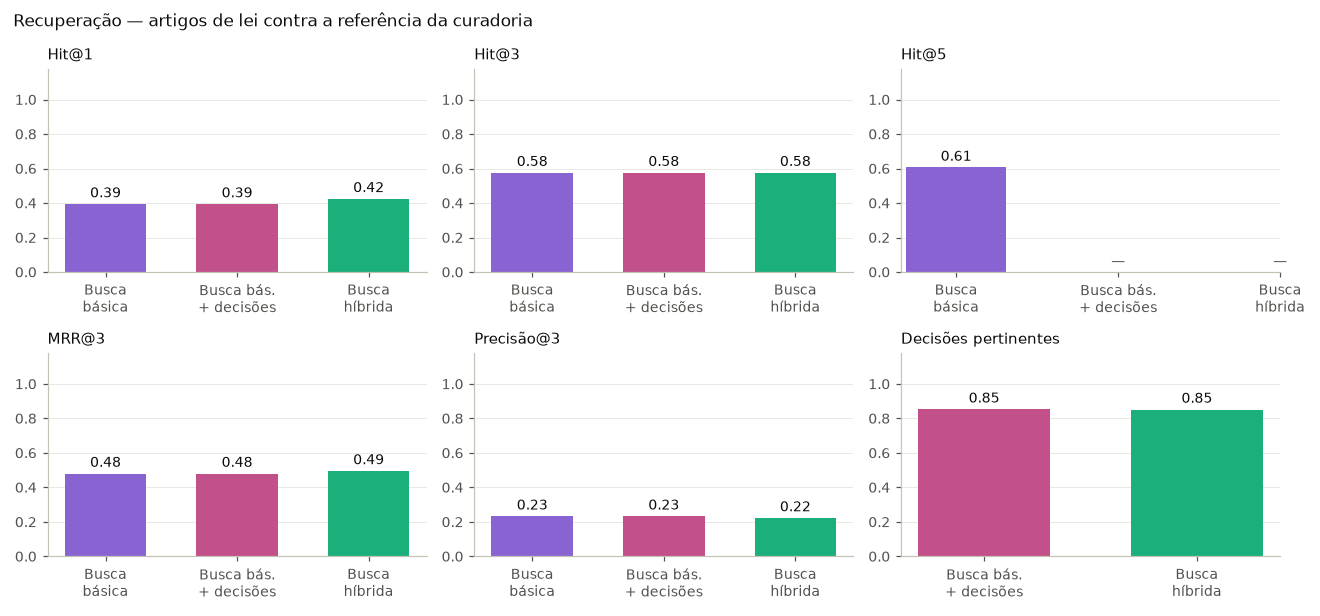

In [2]:
CONFIG_DA_BUSCA = {b: c for c, b in BUSCA_DE.items() if c in RAG_LLM}


def decisoes_pertinentes(busca):
    """Fração das decisões entregues que o juiz julgou pertinentes (NaN se a busca não entrega decisões)."""
    j = df[(df['config'] == CONFIG_DA_BUSCA[busca]) & (df['decisoes_julgadas'] > 0)]
    return j['decisoes_pertinentes'].sum() / j['decisoes_julgadas'].sum() if len(j) else np.nan


tabela = pd.DataFrame({NOMES[b]: {nome: recuperacao(b, col) for col, nome in RECUPERACAO} for b in BUSCAS})
tabela.loc['Tempo de busca (s)'] = [rec.loc[rec['busca'] == b, 'segundos'].mean() for b in BUSCAS]
tabela.loc['Decisões pertinentes'] = [decisoes_pertinentes(b) for b in BUSCAS]
display(tabela.round(2).astype(object).fillna('—'))

fig, axes = plt.subplots(2, 3, figsize=(12, 5.6))
axes = list(axes.flat)
for ax, (col, nome) in zip(axes, RECUPERACAO):
    barras(ax, {b: recuperacao(b, col) for b in BUSCAS}, nome)
barras(axes[-1], {b: decisoes_pertinentes(b) for b in ('basica_jur', 'hibrida')}, 'Decisões pertinentes')
fig.suptitle('Recuperação — artigos de lei contra a referência da curadoria', x=0.01, ha='left', fontsize=11, color=TEXTO)
plt.tight_layout()
plt.show()

**A busca como resposta.** Notas do juiz para o texto dos 3 artigos entregue diretamente. A fidelidade tende ao máximo (a resposta é a fonte); a correção e a aderência mostram se só os artigos já respondem ao que foi perguntado.

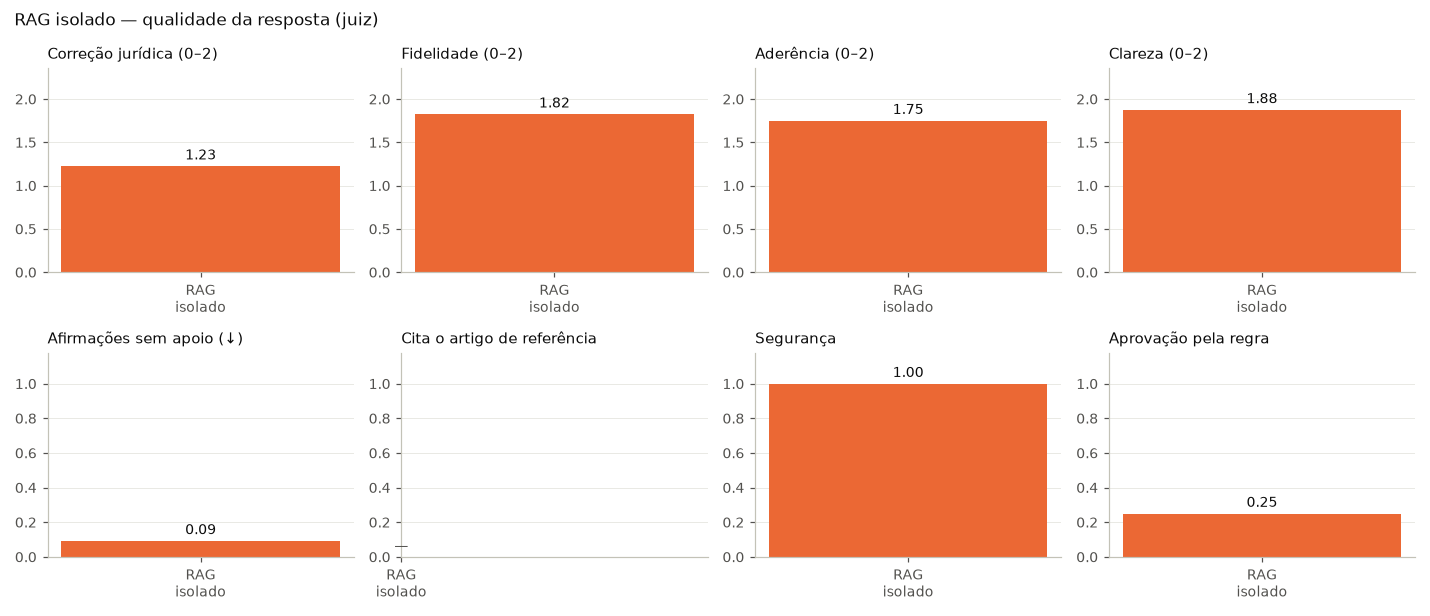

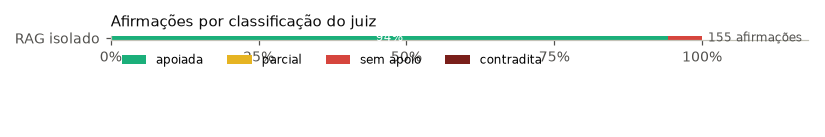

In [3]:
painel_qualidade(['busca_sem_llm'], 'RAG isolado — qualidade da resposta (juiz)')
suporte_afirmacoes(['busca_sem_llm'])

## 2. LLM isolado

O Qwen3 8B responde sozinho, só com o próprio conhecimento. Não há recuperação, então não há métricas de recuperação nem tríade do RAG; o juiz confere as afirmações contra as fontes da busca híbrida, que o modelo não viu. Mede o ponto de partida: o que o modelo acerta e quanto inventa sem contexto.

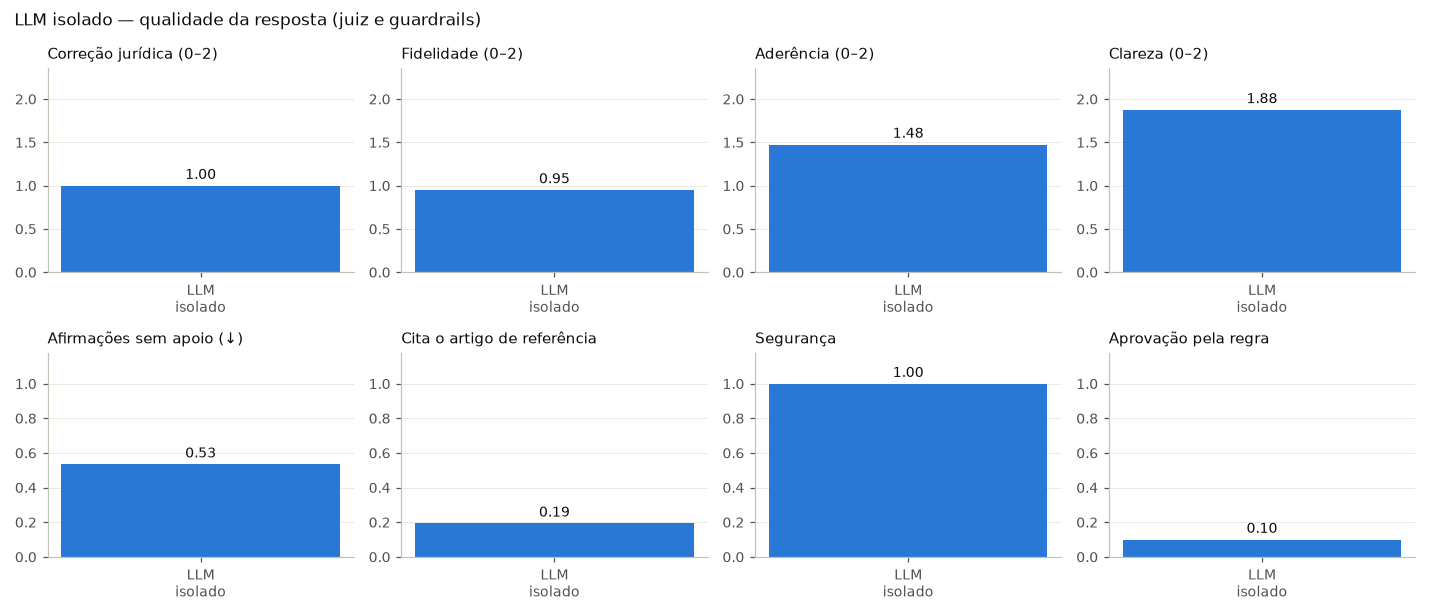

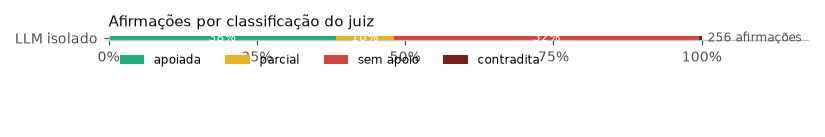

In [4]:
painel_qualidade(['llm_isolado'], 'LLM isolado — qualidade da resposta (juiz e guardrails)')
suporte_afirmacoes(['llm_isolado'])

## 3. RAG × LLM: básico, básico + decisões e híbrido

As três configurações completas, lado a lado e com o LLM isolado como linha de base. Só a busca muda entre elas:

- **básico → básico + decisões:** efeito de entregar 3 decisões (e 3 artigos em vez de 5);
- **básico + decisões → híbrido:** efeito do algoritmo de busca (lexical, RRF e reranker), com a mesma entrega;
- **LLM isolado → qualquer RAG:** ganho de usar RAG.

### 3.1 Recuperação de cada uma

Hit@3 — só a básica acerta: 2 | só a híbrida acerta: 2 | as duas: 17 | nenhuma: 12


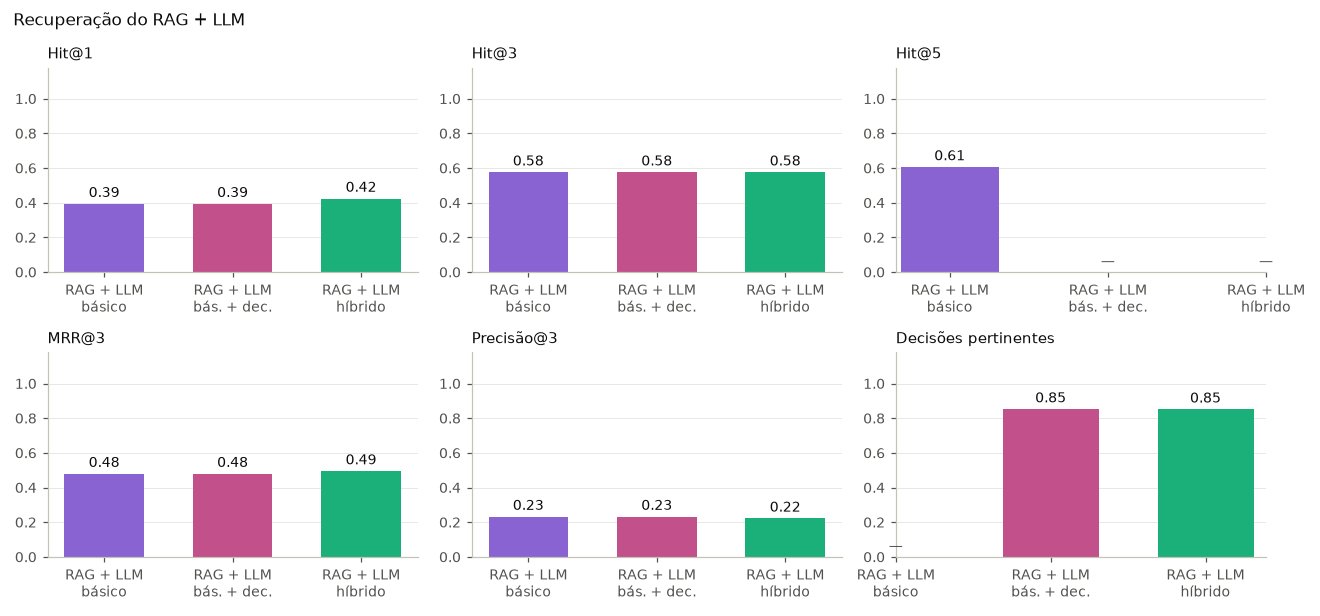

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(12, 5.6))
axes = list(axes.flat)
for ax, (col, nome) in zip(axes, RECUPERACAO):
    barras(ax, {c: recuperacao(BUSCA_DE[c], col) for c in RAG_LLM}, nome)
barras(axes[-1], {c: decisoes_pertinentes(BUSCA_DE[c]) for c in RAG_LLM}, 'Decisões pertinentes')
fig.suptitle('Recuperação do RAG + LLM', x=0.01, ha='left', fontsize=11, color=TEXTO)
plt.tight_layout()
plt.show()
# Por pergunta: onde as buscas divergem no Hit@3
par = com_ref.pivot_table(index='pergunta_id', columns='busca', values='hit_3')
print('Hit@3 — só a básica acerta:', int(((par['basica'] == 1) & (par['hibrida'] == 0)).sum()),
      '| só a híbrida acerta:', int(((par['basica'] == 0) & (par['hibrida'] == 1)).sum()),
      '| as duas:', int(((par['basica'] == 1) & (par['hibrida'] == 1)).sum()),
      '| nenhuma:', int(((par['basica'] == 0) & (par['hibrida'] == 0)).sum()))

### 3.2 Tríade do RAG

Os três vértices na mesma escala (0 a 1). Uma resposta boa precisa dos três: contexto relevante, resposta apoiada nesse contexto e resposta que de fato responde. A fundamentação e a relevância da resposta do LLM isolado aparecem como referência (o contexto dele é vazio).

,LLM isolado,RAG + LLM básico,RAG + LLM básico + decisões,RAG + LLM híbrido
Relevância do contexto,—,0.58,0.58,0.58
Fundamentação,0.37,0.72,0.81,0.83
Relevância da resposta,0.5,0.81,0.88,0.89


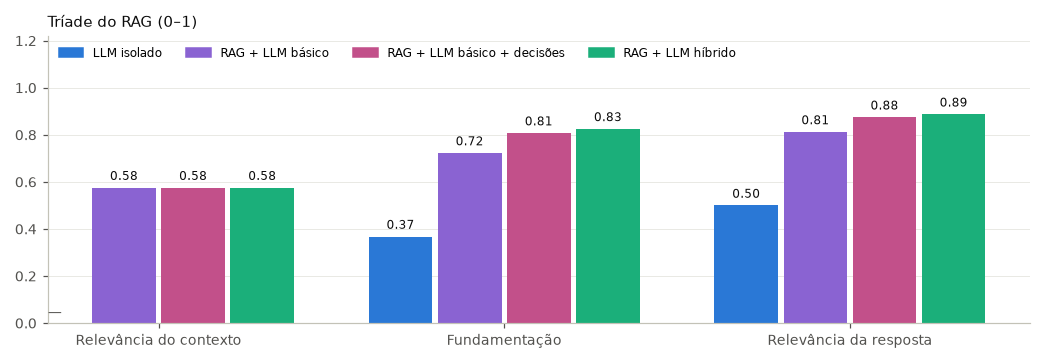

In [6]:
TRIADE = ['Relevância do contexto', 'Fundamentação', 'Relevância da resposta']
NA_TRIADE = ['llm_isolado'] + RAG_LLM
triade = pd.DataFrame({NOMES[c]: [recuperacao(BUSCA_DE[c], 'hit_3') if BUSCA_DE[c] else np.nan,
                                  media(c, 'apoiadas'), media(c, 'correcao') / 2]
                       for c in NA_TRIADE}, index=TRIADE)
display(triade.round(2).astype(object).fillna('—'))

fig, ax = plt.subplots(figsize=(9.5, 3.3))
largura = 0.2
for i, c in enumerate(NA_TRIADE):
    for j, vertice in enumerate(TRIADE):
        v = triade.loc[vertice, NOMES[c]]
        x = j + (i - (len(NA_TRIADE) - 1) / 2) * largura
        if pd.isna(v):
            ax.text(x, 0.03, '—', ha='center', color=TEXTO_2)
            continue
        ax.bar(x, v, width=largura * 0.92, color=CORES[c])
        ax.text(x, v + 0.02, f'{v:.2f}', ha='center', va='bottom', fontsize=8, color=TEXTO)
ax.set_xticks(range(3), TRIADE)
ax.set_ylim(0, 1.22)
ax.grid(axis='y', color=GRADE, linewidth=0.6)
ax.set_axisbelow(True)
ax.set_title('Tríade do RAG (0–1)', loc='left')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=CORES[c], label=NOMES[c]) for c in NA_TRIADE],
          frameon=False, ncol=4, loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

### 3.3 Qualidade do LLM com RAG

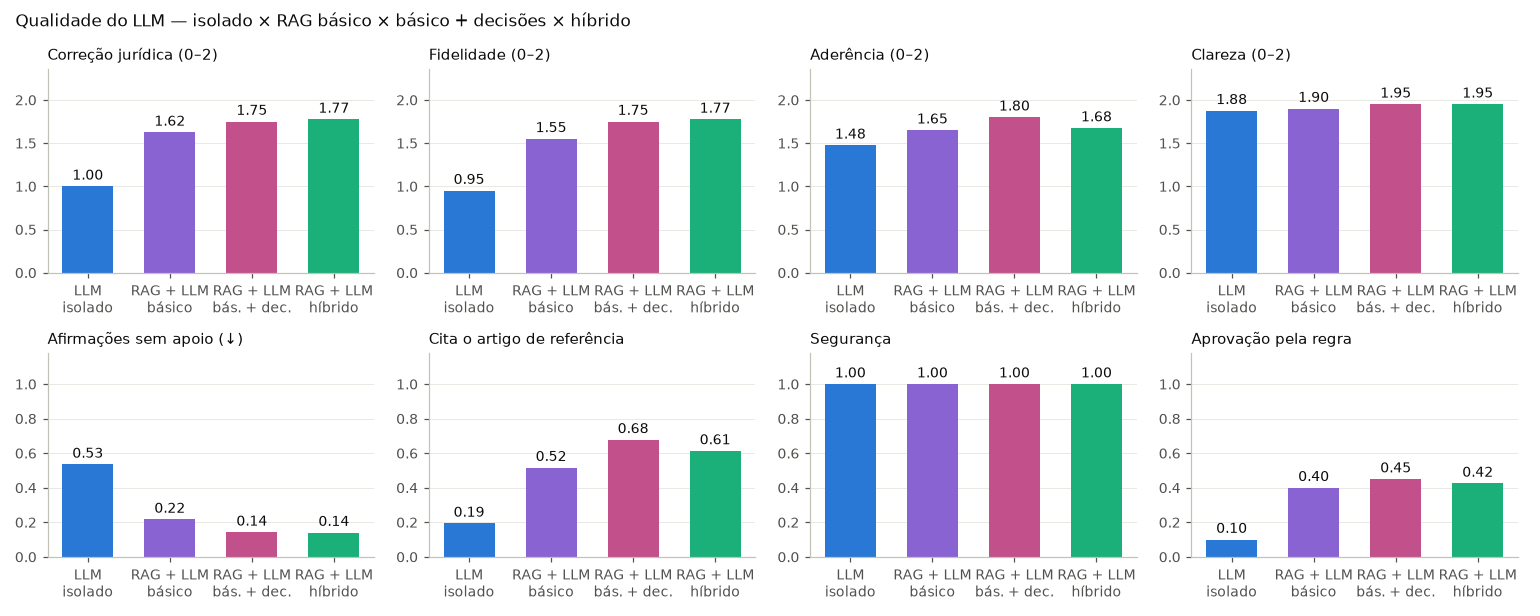

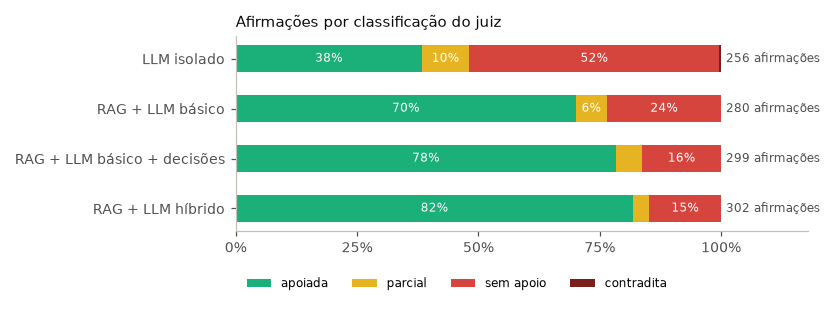

In [7]:
painel_qualidade(['llm_isolado'] + RAG_LLM, 'Qualidade do LLM — isolado × RAG básico × básico + decisões × híbrido')
suporte_afirmacoes(['llm_isolado'] + RAG_LLM)

## 4. Comparativo das cinco configurações

Todas as métricas numa tabela. "não se aplica": recuperação no LLM isolado; citação do artigo de referência no RAG isolado (a resposta é o próprio artigo).

,RAG isolado,LLM isolado,RAG + LLM básico,RAG + LLM básico + decisões,RAG + LLM híbrido
Correção jurídica (0–2),1.23,1.00,1.62,1.75,1.77
Fidelidade (0–2),1.82,0.95,1.55,1.75,1.77
Aderência (0–2),1.75,1.48,1.65,1.80,1.68
Clareza (0–2),1.88,1.88,1.90,1.95,1.95
Afirmações sem apoio,0.09,0.53,0.22,0.14,0.14
Cita o artigo de referência,não se aplica,0.19,0.52,0.68,0.61
Segurança,1.00,1.00,1.00,1.00,1.00
Aprovação pela regra,0.25,0.10,0.40,0.45,0.42
Latência (s),16.10,19.91,34.14,41.18,57.86
Tempo de inferência (s),0.00,19.91,33.93,40.33,41.75


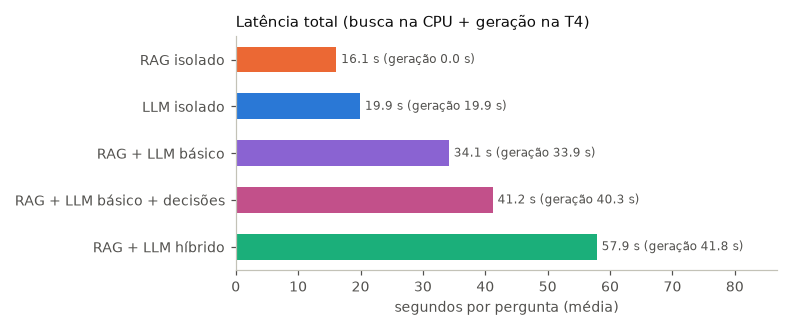

In [8]:
LINHAS = [('Correção jurídica (0–2)', 'correcao'), ('Fidelidade (0–2)', 'fidelidade'), ('Aderência (0–2)', 'aderencia'),
          ('Clareza (0–2)', 'clareza'), ('Afirmações sem apoio', 'sem_apoio'), ('Cita o artigo de referência', 'cita_referencia'),
          ('Segurança', 'seguranca'), ('Aprovação pela regra', 'aprovada'), ('Latência (s)', 'latencia_s'),
          ('Tempo de inferência (s)', 'inferencia_s')]
busca_cfg = BUSCA_DE
geral = {}
for c in CONFIGS:
    col = {nome: media(c, coluna) for nome, coluna in LINHAS}
    if c == 'busca_sem_llm':
        col['Cita o artigo de referência'] = 'não se aplica'
    for coluna, nome in [('hit_3', 'Hit@3'), ('rr_3', 'MRR@3')]:
        col[nome] = recuperacao(busca_cfg[c], coluna) if busca_cfg[c] else 'não se aplica'
    geral[NOMES[c]] = col
geral = pd.DataFrame(geral)
display(geral.map(lambda v: f'{v:.2f}' if isinstance(v, float) and not pd.isna(v) else ('—' if pd.isna(v) else v)))

fig, ax = plt.subplots(figsize=(7.2, 3))
y = list(range(len(CONFIGS)))[::-1]
for yi, c in zip(y, CONFIGS):
    total, inferencia = media(c, 'latencia_s'), media(c, 'inferencia_s')
    if pd.isna(total):
        ax.text(0.5, yi, '—', va='center', color=TEXTO_2)
        continue
    ax.barh(yi, total, color=CORES[c], height=0.55)
    ax.text(total + 0.8, yi, f'{total:.1f} s (geração {inferencia:.1f} s)', va='center', color=TEXTO_2, fontsize=8)
ax.set_yticks(y, [NOMES[c] for c in CONFIGS])
ax.set_xlim(0, np.nanmax([media(c, 'latencia_s') for c in CONFIGS]) * 1.5)
ax.set_xlabel('segundos por pergunta (média)')
ax.set_title('Latência total (busca na CPU + geração na T4)', loc='left')
plt.tight_layout()
plt.show()

## 5. Validador

Limites mínimos declarados para o assistente em produção (não calibrados nos resultados deste notebook). O RAG + LLM híbrido é a configuração que vai para produção e precisa passar em todos; as outras aparecem para mostrar a distância até o limite. Depois de qualquer mudança no sistema, este painel diz se ela pode seguir.

In [9]:
LIMITES = [('Hit@3 (recuperação)', 'hit_3', '≥', 0.70), ('Fundamentação (afirmações apoiadas)', 'apoiadas', '≥', 0.80),
           ('Afirmações sem apoio', 'sem_apoio', '≤', 0.10), ('Correção jurídica (0–2)', 'correcao', '≥', 1.50),
           ('Aderência (0–2)', 'aderencia', '≥', 1.50), ('Segurança', 'seguranca', '≥', 1.00)]
painel = []
for nome, coluna, sinal, limite in LIMITES:
    linha = {'critério': f'{nome} {sinal} {limite:.2f}'}
    for c in CONFIGS:
        if coluna == 'hit_3':
            v = recuperacao(busca_cfg[c], 'hit_3') if busca_cfg[c] else np.nan
        else:
            v = media(c, coluna)
        if pd.isna(v):
            linha[NOMES[c]] = '—'
            continue
        ok = v >= limite if sinal == '≥' else v <= limite
        linha[NOMES[c]] = f'{"✅" if ok else "❌"} {v:.2f}'
    painel.append(linha)
painel = pd.DataFrame(painel).set_index('critério')
display(painel)
hib = painel[NOMES['rag_hibrido']]
falhas = [i for i, v in hib.items() if v.startswith('❌')]
display(Markdown('**RAG + LLM híbrido: ' + ('passa em todos os critérios.**' if not falhas and not hib.eq('—').any()
                 else f'não passa em {len(falhas)} critério(s): ' + '; '.join(falhas) + '.**' if falhas
                 else 'há critérios sem dado.**')))

,RAG isolado,LLM isolado,RAG + LLM básico,RAG + LLM básico + decisões,RAG + LLM híbrido
critério,,,,,
Hit@3 (recuperação) ≥ 0.70,❌ 0.58,—,❌ 0.58,❌ 0.58,❌ 0.58
Fundamentação (afirmações apoiadas) ≥ 0.80,✅ 0.91,❌ 0.37,❌ 0.72,✅ 0.81,✅ 0.83
Afirmações sem apoio ≤ 0.10,✅ 0.09,❌ 0.53,❌ 0.22,❌ 0.14,❌ 0.14
Correção jurídica (0–2) ≥ 1.50,❌ 1.23,❌ 1.00,✅ 1.62,✅ 1.75,✅ 1.77
Aderência (0–2) ≥ 1.50,✅ 1.75,❌ 1.48,✅ 1.65,✅ 1.80,✅ 1.68
Segurança ≥ 1.00,✅ 1.00,✅ 1.00,✅ 1.00,✅ 1.00,✅ 1.00


**RAG + LLM híbrido: não passa em 2 critério(s): Hit@3 (recuperação) ≥ 0.70; Afirmações sem apoio ≤ 0.10.**

## 6. Observador: onde a qualidade se perde

Para cada pergunta reprovada no RAG + LLM híbrido, a etapa provável da falha:

- **busca:** nenhum artigo de referência entre os 3 primeiros (Hit@3 = 0);
- **geração:** a busca acertou, mas há afirmações sem apoio ou a correção ficou abaixo de 2;
- **comportamento:** a aderência ficou abaixo de 2 (não seguiu a ação esperada).

Uma pergunta pode ter mais de uma etapa. Perguntas sem artigo de referência na curadoria não têm diagnóstico de busca.

In [10]:
h = df[df['config'] == 'rag_hibrido'].set_index('pergunta_id')
hit = com_ref[com_ref['busca'] == 'hibrida'].set_index('pergunta_id')['hit_3']
etapas = []
for qid, r in h[h['veredito_regra'] == 'reprovada'].iterrows():
    e = []
    if hit.get(qid) == 0:
        e.append('busca')
    if (r['afirmacoes_sem_apoio'] + r['afirmacoes_contradita'] > 0) or r['correcao'] < 2:
        if hit.get(qid) != 0:
            e.append('geração')
    if r['aderencia'] < 2:
        e.append('comportamento')
    etapas.append(dict(pergunta_id=qid, acao=r['acao'], hit_3=hit.get(qid), correcao=r['correcao'],
                       fidelidade=r['fidelidade'], aderencia=r['aderencia'],
                       sem_apoio=int(r['afirmacoes_sem_apoio'] + r['afirmacoes_contradita']), etapas=', '.join(e) or '—'))
etapas = pd.DataFrame(etapas)
print('reprovadas no RAG + LLM híbrido:', len(etapas), 'de', int(h['veredito_regra'].notna().sum()))
if len(etapas):
    contagem = pd.Series([x for s in etapas['etapas'] for x in s.split(', ') if x != '—']).value_counts()
    display(contagem.rename('perguntas').to_frame())
    display(etapas.sort_values('pergunta_id').set_index('pergunta_id'))

reprovadas no RAG + LLM híbrido: 23 de 40


,perguntas
geração,14
comportamento,12
busca,7


,acao,hit_3,correcao,fidelidade,aderencia,sem_apoio,etapas
pergunta_id,,,,,,,
q09_p1_JUS-002,responder,0.0,2,1,2,1,busca
q09_p1_JUS-004,responder,0.0,1,2,2,0,busca
q09_p1_JUS-010,responder,1.0,2,2,2,1,geração
q09_p1_JUS-013,responder,1.0,2,2,1,0,comportamento
q09_p1_JUS-014,responder,1.0,2,1,2,2,geração
q09_p1_JUS-016,orientar_sem_aconselhar,1.0,1,1,1,3,"geração, comportamento"
q09_p1_JUS-019,responder,0.0,2,2,2,3,busca
q09_p1_JUS-022,orientar_sem_aconselhar,NaN,2,2,1,1,"geração, comportamento"
q09_p1_JUS-024,orientar_sem_aconselhar,0.0,1,1,1,6,"busca, comportamento"


## 7. Conclusões

Resultados das 40 perguntas JUS com busca, julgadas pelo Gemma 3 27B (200 julgamentos válidos).

| | RAG isolado | LLM isolado | RAG + LLM básico | RAG + LLM básico + decisões | RAG + LLM híbrido |
|---|---|---|---|---|---|
| Hit@3 (artigos de lei) | 0,58 | — | 0,58 | 0,58 | 0,58 |
| Correção jurídica (0–2) | 1,23 | 1,00 | 1,62 | 1,75 | **1,78** |
| Fidelidade (0–2) | 1,82 | 0,95 | 1,55 | 1,75 | 1,78 |
| Aderência (0–2) | 1,75 | 1,48 | 1,65 | **1,80** | 1,68 |
| Afirmações apoiadas (média por resposta) | 91% | 37% | 72% | 81% | 83% |
| Afirmações sem apoio (média por resposta) | 9% | 53% | 22% | 14% | 14% |
| Cita o artigo de referência | — | 19% | 52% | **68%** | 61% |
| Decisões pertinentes | — | — | — | 85% | 85% |
| Aprovadas pela regra | 10 | 4 | 16 | **18** | 17 |
| Latência (s) | 16 | 20 | 34 | **41** | 58 |

1. **RAG vale a pena.** Sem fontes, o Qwen3 8B acerta metade do que deveria (correção 1,00) e mais da metade das afirmações não tem apoio. Com qualquer RAG, a correção sobe para 1,6–1,8 e a alucinação cai para menos da metade. A segurança fica em 100% em todas as configurações: os guardrails não dependem da busca.
2. **A busca sozinha é fiel, mas não responde.** O texto dos artigos é a própria fonte (91% apoiado), mas a correção fica em 1,23: os artigos nem sempre respondem ao que foi perguntado, e sem redação a pessoa recebe lei crua. O LLM é o que transforma a fonte em resposta.
3. **O ganho do RAG híbrido sobre o básico vem das decisões, não do algoritmo de busca.** Entregar 3 decisões (e 3 artigos em vez de 5) leva o básico de 1,62 para 1,75 de correção (melhor em 9 perguntas, pior em 4) e de 22% para 14% de afirmações sem apoio. Com a mesma entrega, a busca híbrida (lexical + RRF + reranker) e a semântica pura ficam praticamente iguais: correção 1,78 × 1,75 (6 perguntas melhores, 5 piores), mesmas afirmações sem apoio, mesmas decisões pertinentes (85%) e 17 × 18 aprovadas.
4. **Na legislação, as três buscas empatam** pelo gabarito da curadoria (Hit@3 = 0,58; MRR@3 = 0,48–0,49). A busca semântica pura leva 0,2 s (0,85 s com decisões); a híbrida, 16 s na CPU, quase todo o tempo no reranker.
5. **O validador reprova todas as configurações com RAG nos mesmos 2 critérios**: Hit@3 abaixo de 0,70 e afirmações sem apoio acima de 10%. Das 23 reprovadas do híbrido, a falha está mais na geração (14) e no comportamento (12) do que na busca (7).

**Implicação.** Nesta amostra, o RAG básico + decisões entrega a mesma qualidade do híbrido com 29% menos latência total (41 s × 58 s) e uma busca cerca de 19 vezes mais rápida. A busca lexical e o reranker não se pagam neste conjunto. Antes de simplificar a arquitetura, vale confirmar em mais perguntas: 40 respostas e um único juiz não separam diferenças pequenas (6 × 5 perguntas).

**Próximos passos sugeridos.**

- Repetir a comparação básico + decisões × híbrido num conjunto maior (as 111 perguntas da geração) antes de decidir pela busca mais simples.
- Investigar o reranker na jurisprudência: com 256 tokens por par, ele lê só metade da janela de 500 tokens (o notebook 01 da integração já registrava MRR melhor sem reranker).
- Atacar as afirmações sem apoio na geração (prompt ou guardrail que exija `[Fonte N]` por afirmação) e o comportamento em `orientar_sem_aconselhar`.
- Revisar o gabarito de artigos da curadoria (7 perguntas sem artigo de referência e referências marcadas como pendentes) antes de usar o Hit@3 como critério de corte.
- Validar o juiz com rótulos humanos (20–30 respostas): ele aprova pelo próprio veredito 29 das 40 respostas do LLM isolado, contra 4 pela regra fixa.